# ML Zoomcamp 2026 — Homework 4

## Evaluation Metrics for Classification

This notebook reproduces the six homework answers using the course’s pinned 2026 lead-scoring dataset. It follows the [official instructions](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/04-evaluation/homework.md).

Missing categorical values are filled with `NA`, missing numerical values with `0.0`, and the required 60/20/20 split uses `random_state=1`. The unused held-out test split is kept out of evaluation and tuning.

## Run the analysis

The full implementation is in `solution.py` so the same logic can also be run from a terminal with `python solution.py`.

In [1]:
from solution import main

results = main()

ML Zoomcamp 2026 — Homework 4 results
Dataset: 5000 rows; split train/validation/test = 3000/1000/1000

Q1 — ROC AUC feature importance (direction-adjusted):
  lead_score: 0.788225
  interaction_count: 0.764920
  number_of_courses_viewed: 0.722989
  annual_income: 0.608198
  Answer: lead_score

Q2 — Validation ROC AUC: 0.731822 (rounds to 0.732)

Q3 — Closest precision/recall threshold: 0.63 (P=0.7328, R=0.7253, gap=0.0075)

Q4 — Best F1 threshold: 0.41 (F1=0.757616)

Q5 — Fold AUC scores: [0.73056, 0.729573, 0.736343, 0.741245, 0.720914]
  Population standard deviation: 0.006853 (rounds to 0.007)

Q6 — 5-fold results:
  C=1e-06: mean AUC=0.616734, std=0.018670
  C=0.001: mean AUC=0.749172, std=0.009996
  C=1: mean AUC=0.731727, std=0.006853
  Best C: 0.001

Figures saved to: /workspace/hw04-evaluation-metrics/figures


## Selected answers

The values below are the exact results and the matching choices in the homework form.

In [2]:
import pandas as pd
from IPython.display import display

answers = pd.DataFrame([
    {"Question": "Q1 — highest single-feature ROC AUC", "Computed result": f"{results['q1_answer']} ({results['q1_feature_auc'][results['q1_answer']]:.6f})", "Select": results['q1_answer']},
    {"Question": "Q2 — validation ROC AUC", "Computed result": f"{results['q2_validation_auc']:.6f}", "Select": f"{results['q2_validation_auc']:.3f}"},
    {"Question": "Q3 — closest precision/recall threshold", "Computed result": f"{results['q3_precision_recall_closest_threshold']:.2f} (P={results['q3_precision']:.4f}, R={results['q3_recall']:.4f})", "Select": f"{results['q3_precision_recall_closest_threshold']:.2f}"},
    {"Question": "Q4 — threshold with maximum F1", "Computed result": f"{results['q4_best_f1_threshold']:.2f} (F1={results['q4_best_f1']:.6f})", "Select": f"{results['q4_best_f1_threshold']:.2f}"},
    {"Question": "Q5 — 5-fold AUC standard deviation", "Computed result": f"{results['q5_fold_auc_std_population']:.6f}", "Select": f"{results['q5_fold_auc_std_population']:.3f}"},
    {"Question": "Q6 — best C", "Computed result": f"{results['q6_best_c']:g} (mean AUC={results['q6_tuning'][results['q6_best_c']]['mean_auc']:.6f})", "Select": f"{results['q6_best_c']:g}"},
])
display(answers)

,Question,Computed result,Select
0,Q1 — highest single-feature ROC AUC,lead_score (0.788225),lead_score
1,Q2 — validation ROC AUC,0.731822,0.732
2,Q3 — closest precision/recall threshold,"0.63 (P=0.7328, R=0.7253)",0.63
3,Q4 — threshold with maximum F1,0.41 (F1=0.757616),0.41
4,Q5 — 5-fold AUC standard deviation,0.006853,0.007
5,Q6 — best C,0.001 (mean AUC=0.749172),0.001


## Precision, recall, and F1 curves

The Q3 choice is the evaluated threshold with the smallest absolute precision–recall gap, excluding thresholds where both values are zero. Q4 selects the threshold with the highest F1 score.

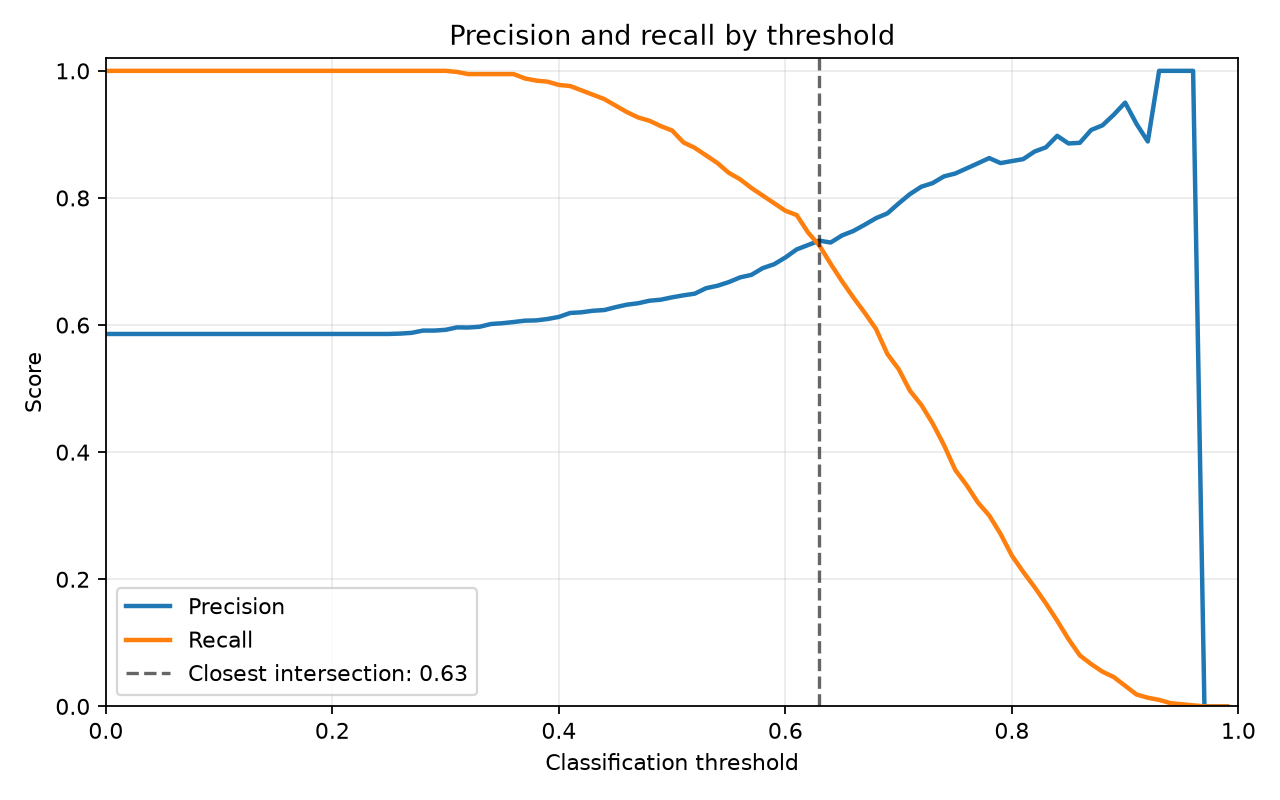

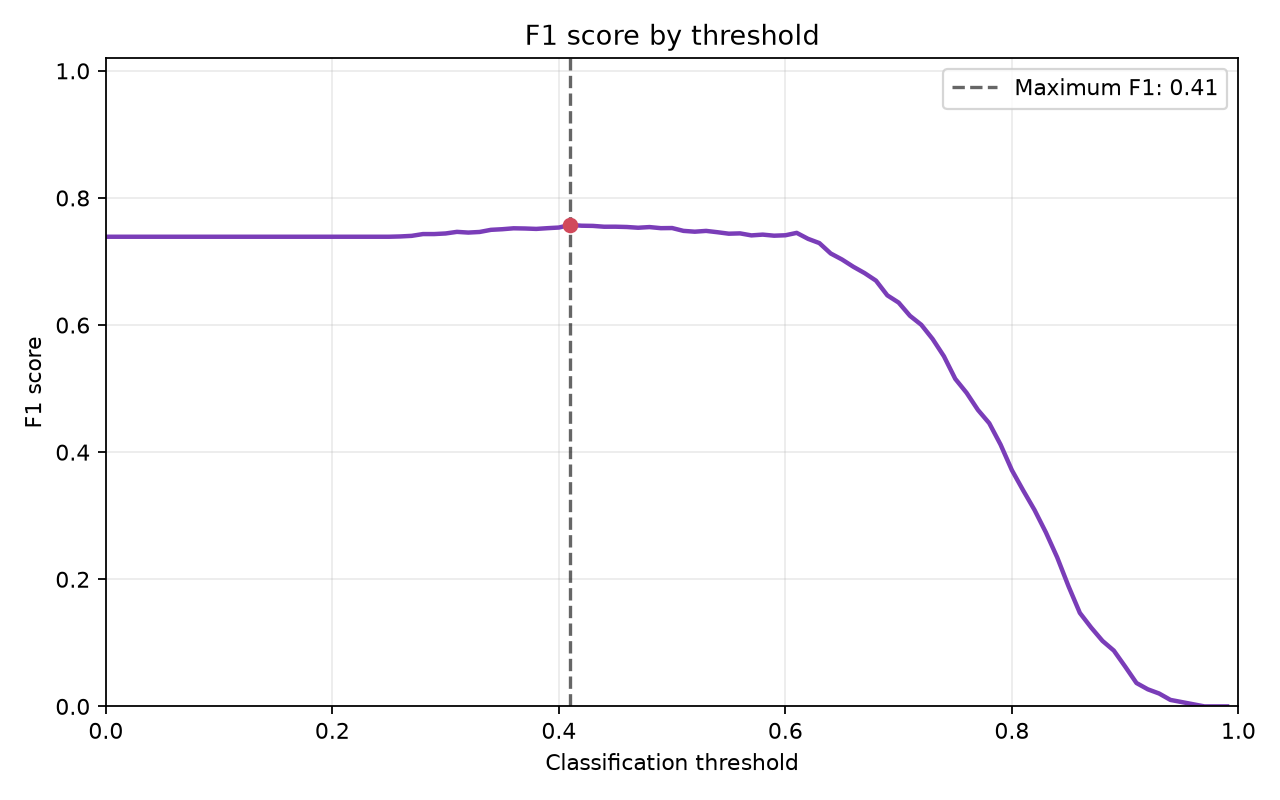

In [3]:
from IPython.display import Image, display

display(Image(filename="figures/precision_recall_by_threshold.png"))
display(Image(filename="figures/f1_by_threshold.png"))

## Cross-validation

Five folds are created from the full 80% training portion using `KFold(n_splits=5, shuffle=True, random_state=1)`. Each fold fits its own `DictVectorizer` and logistic regression. The best `C` is selected by rounded mean ROC AUC, then lower rounded standard deviation, then smaller `C`, as specified by the release checker.